# Evaluate Models on the Test Data

6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

### Load all Modals

In [2]:
simple_head = keras.saving.load_model('models/frozen_base_features_dropout.keras')

data_augmented = keras.saving.load_model('models/frozen_base_augmented_data.keras')

tuned_head = keras.saving.load_model('models/frozen_base_tuned_head.keras')

tuned_deeper_head = keras.saving.load_model('models/frozen_base_deeper_head.keras')

# fine-tuned model with data augmentation
fine_tuned_data_augmented = keras.saving.load_model('models/fine_tuned_data_augmented.keras')

# fine-tuned model with a simple head
fine_tuned_simple_head = keras.saving.load_model('models/fine_tuned_simple_head.keras')

### Load Test Data

In [3]:
# Loading the images

IMAGE_SIZE = (160, 160)

FLOWERS = Path("./data")

SEED = 42

def load_images(split, shuffle):
    return keras.utils.image_dataset_from_directory(
       FLOWERS / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=SEED
    )

test_ds = load_images("test", shuffle=False)

class_names = test_ds.class_names

print("Classes:", class_names)

Found 30 files belonging to 3 classes.
Classes: ['rose', 'sunflower', 'tulip']


### Evaluate Models on Test Data

In [4]:
test_results = {}

In [5]:
# Extract features from the datasets using the frozen base model


base = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

def extract_features(dataset):
    """Run the frozen base over every batch of a dataset; return the feature vectors and the labels."""
    all_features = []
    all_labels = []
    for images, labels in dataset:  # one batch of up to 32 images at a time
        images = mobilenet_v2.preprocess_input(images)  # scale the pixels from 0 to 255 to -1 to 1
        features = base.predict(images, verbose=0)  # one row of 1,280 numbers per image
        all_features.append(features)
        all_labels.append(labels.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)  # stack the batches into one table



In [6]:
# Run tests

models_dict = {
    "Frozen-Base-Features-Dropout": simple_head,
    "Frozen-Base-Augmented-Data": data_augmented,
    "Frozen-Base-Tuned-Head": tuned_head,
    "Frozen-Base-Deeper-Head": tuned_deeper_head,
    "Fine-Tuned-Augmented-Data": fine_tuned_data_augmented,
    "Fine-Tuned-Simple-Head": fine_tuned_simple_head
}


X_test, y_test = extract_features(test_ds)

for model_name, model in models_dict.items():
    print(f"Testing model: {model_name}")
    print(model)
    test_results[model_name] = None

    if model_name in ["Frozen-Base-Features-Dropout", "Frozen-Base-Tuned-Head", "Frozen-Base-Deeper-Head"]:
        test_results[model_name] = model.evaluate(X_test, y_test, verbose=0) 
    else:
        test_results[model_name] = model.evaluate(test_ds, verbose=0) 

    print(f"Results for {model_name}: {test_results[model_name]}")

Testing model: Frozen-Base-Features-Dropout
<Sequential name=sequential, built=True>
Results for Frozen-Base-Features-Dropout: [0.19452014565467834, 0.8999999761581421]
Testing model: Frozen-Base-Augmented-Data
<Sequential name=sequential, built=True>
Results for Frozen-Base-Augmented-Data: [0.18914781510829926, 0.9333333373069763]
Testing model: Frozen-Base-Tuned-Head
<Sequential name=sequential, built=True>
Results for Frozen-Base-Tuned-Head: [0.18955165147781372, 0.9333333373069763]
Testing model: Frozen-Base-Deeper-Head
<Sequential name=sequential, built=True>
Results for Frozen-Base-Deeper-Head: [0.30384981632232666, 0.9666666388511658]
Testing model: Fine-Tuned-Augmented-Data
<Sequential name=sequential, built=True>
Results for Fine-Tuned-Augmented-Data: [0.10904289036989212, 0.9666666388511658]
Testing model: Fine-Tuned-Simple-Head
<Sequential name=sequential, built=True>
Results for Fine-Tuned-Simple-Head: [0.1313771903514862, 0.9333333373069763]


In [7]:

results_table = pd.DataFrame(test_results, index=["Test Loss", "Test Accuracy"]).T

# load validation accuracy results
import json
with open("results.json", "r") as f:
    results = json.load(f)

# Add validation accuracy results to the table
for model_name, val_acc in results.items():
    if model_name in results_table.index:
        results_table.loc[model_name, "Validation Accuracy"] = val_acc

results_table = results_table.sort_values(by="Validation Accuracy", ascending=False).round(4)

results_table.sort_values(by="Test Accuracy", ascending=False).round(4)

,Test Loss,Test Accuracy,Validation Accuracy
Fine-Tuned-Augmented-Data,0.1090,0.9667,0.8167
Frozen-Base-Deeper-Head,0.3038,0.9667,0.7500
Fine-Tuned-Simple-Head,0.1314,0.9333,0.8333
Frozen-Base-Augmented-Data,0.1891,0.9333,0.8167
Frozen-Base-Tuned-Head,0.1896,0.9333,0.8000
Frozen-Base-Features-Dropout,0.1945,0.9000,0.8667


### Question: 
Is the validation accuracy of your chosen model a fair estimate of its test accuracy?

### Answer:
Both the data sets for validation and test are very small. The differences might well be an artefact.

The model with the frozen base and a deeper head has the largest gap between validation and test accuracy with around 21% difference,
indicating that the difference might be the result of the size of the data sets and not real metric of performance.

With such a small data set (30 for the test set), 21% difference means 7 pictures are predicted differently. 

## Confusion Matrix

Fine-tuned model with augmented data, test accuracy: 0.967


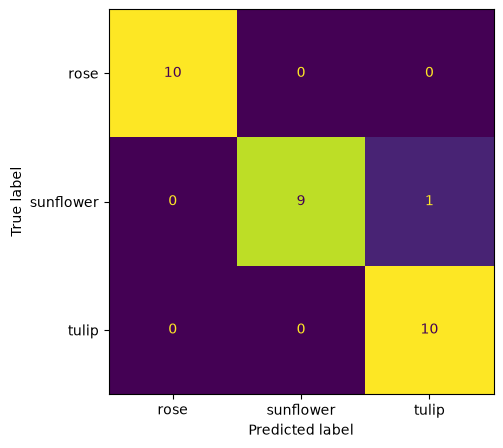

In [8]:
test_accuracy = fine_tuned_data_augmented.evaluate(test_ds, verbose=0)[1]
print(f"Fine-tuned model with augmented data, test accuracy: {test_accuracy:.3f}")

y_pred = fine_tuned_data_augmented.predict(test_ds, verbose=0).argmax(axis=1)  # the class with the highest probability
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, colorbar=False, ax=ax)
ax.grid(False)
plt.show()

## False Prediction

1 of 30 test images are misclassified


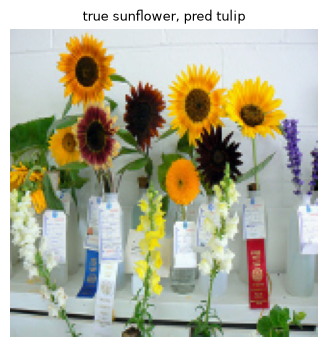

In [9]:
wrong = np.flatnonzero(y_pred != y_test)
print(f"{len(wrong)} of {len(y_test)} test images are misclassified")

# X_test holds the feature vectors, so take the raw photos from test_ds (same order, shuffle=False)
test_images = np.concatenate([images.numpy() for images, _ in test_ds])

fig, axes = plt.subplots(1, len(wrong), figsize=(4 * len(wrong), 4), squeeze=False)
for ax, i in zip(axes[0], wrong):
    ax.imshow(test_images[i].astype("uint8"))
    ax.set_title(f"true {class_names[y_test[i]]}, pred {class_names[y_pred[i]]}", fontsize=9)
    ax.axis("off")
plt.show()

The falsely predicted picture shows many flowers of different kinds. It is not even clear by the image's composition, which flower should be predicted. (All flowers are more or less on the same plane and have the same size.)

In [10]:
# Print all the probabilities for the test images in a data frame

y_prob = fine_tuned_data_augmented.predict(test_ds, verbose=0)  # probabilities for each class
df = pd.DataFrame(y_prob, columns=class_names)
df_percent = df * 100
df_percent.astype(int)

# Only print one column for predicted label and the corresponding probability
predicted_labels = df.idxmax(axis=1)
predicted_probs = df.max(axis=1)
df_predicted = pd.DataFrame({
    'Predicted Label': predicted_labels,
    'Probability': predicted_probs
})
# Sort first label, then probability
df_predicted =df_predicted.sort_values(by=['Predicted Label', 'Probability'], ascending=[True, False])
df_predicted['Probability (%)'] = round(df_predicted['Probability'] * 100)
df_predicted = df_predicted.drop(columns=['Probability'])

df_predicted


,Predicted Label,Probability (%)
1,rose,100.0
2,rose,100.0
3,rose,100.0
9,rose,100.0
5,rose,99.0
6,rose,99.0
7,rose,98.0
8,rose,96.0
4,rose,88.0
0,rose,78.0


In [11]:
# Display the average probability for each predicted label
df_predicted.groupby('Predicted Label')['Probability (%)'].mean()


Predicted Label
rose         95.800000
sunflower    93.444444
tulip        89.363636
Name: Probability (%), dtype: float64

# Model Performance

The model performs really good on the small test set with an accuracy of 96.7%.

It predicted 29 pictures correct and only one wrong.

It shows the most certainty on roses with an average test accuracy of 95.8%, followed by sunflowers with 93.4% and performed the worst on tulips with an accuracy of 89.4%.

# Recommendation

The employees working with the model could double-check the predictions for tulips, although a score of 89% is fairly good.

# Outline

The test set is very small with just 10 pictures per flower.

To actually evaluate the model's performance, more data should be collected.